# Question
What is the probability that an AI Agent that is randomly moving in PacMan picks up it's first orb in 10 seconds?

### Simulation
I will simulate this by giving an AI Agent access to PacMan or some form of it and only tell it that it can move around.

In [13]:
from IPython.display import clear_output, display
import matplotlib.pyplot as plt
import gymnasium as gym
import ale_py
import time

In [14]:
gym.register_envs(ale_py)
#gym.pprint_registry()

In [15]:
env = gym.make('ALE/Pacman-v5', render_mode='rgb_array')
observation, info = env.reset()

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

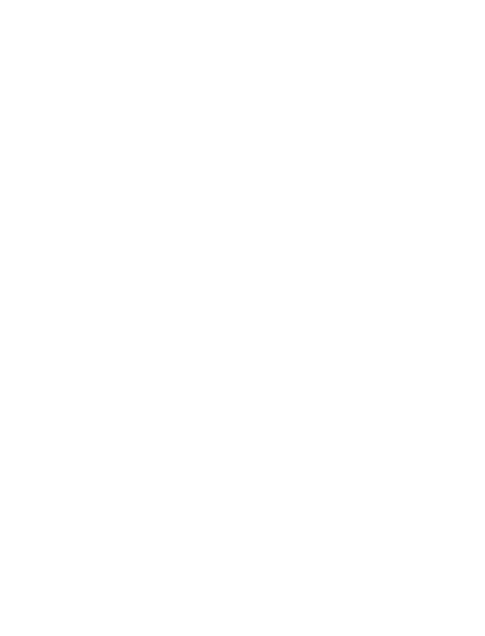

In [16]:
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')

In [17]:
max_steps_10s = 150
target_fps = 30
frame_duration = 1 / target_fps

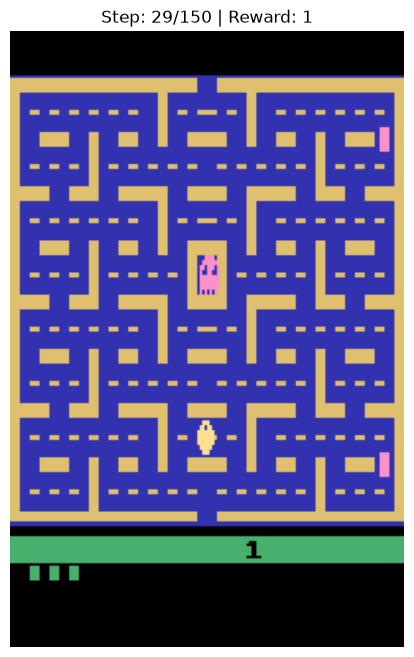


Success! Agent collected an orb at step 29.


In [18]:
total_reward = 0

for step in range(max_steps_10s):
  action = env.action_space.sample()
  observation, reward, terminated, truncated, info = env.step(action)
  total_reward += reward
  clear_output(wait=True)
  ax.clear()
  ax.imshow(env.render())
  ax.set_title(
    f"Step: {step}/{max_steps_10s} | Reward: {total_reward:.0f}",
    fontsize=12,
  )
  ax.axis("off")
  display(fig)
  time.sleep(frame_duration)
  if reward > 0:
    print(f"\nSuccess! Agent collected an orb at step {step}.")
    break
  if terminated or truncated:
    print("\nEpisode ended early (ghost caught or game over).")
    break

plt.close(fig)
env.close()

# Conclusion
There is a 100% probability of the Agent collecting an orb within the first 10 seconds of gameplay. Following a static 28 step introduction, the Agent's initial movement on step 29 consistently results in immediate orb collection.